# Reproduce the frozen A100 experiment after runtime loss

The original recovery completed training and began holdout evaluation before its runtime disappeared. This replay changes no model, data, precision, schedule, threshold rule or candidate selection. It recreates all original checkpoint bytes, requires both saved new checkpoints and all 36 captured validation summaries to match, then repeats the fixed evaluation to recover complete artifacts. The 453-page test is already partially consumed; this is a repeat measurement, not another model-selection experiment.

### 1. Install the same pinned environment

In [ ]:
import os, subprocess, sys
from pathlib import Path
os.environ.update(USE_TF='0', USE_FLAX='0', WANDB_MODE='disabled', TOKENIZERS_PARALLELISM='false')
packages = ['torch==2.9.1','sentence-transformers==5.1.2','transformers==4.57.3','datasets==4.4.1','xgboost==3.1.2','scikit-learn==1.7.2','numpy==2.3.5','scipy==1.16.3','beautifulsoup4==4.14.2','accelerate==1.11.0']
for command in [[sys.executable,'-m','pip','uninstall','-y','torchvision','torchaudio'], [sys.executable,'-m','pip','install','-q'] + packages]:
    with subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True) as process:
        for line in process.stdout:
            print(line, end='', flush=True)
        if process.wait():
            raise RuntimeError('Environment setup failed')
print('Pinned environment installed. Model training uses fresh Python subprocesses.')


Found existing installation: torchvision 0.26.0+cu128


Uninstalling torchvision-0.26.0+cu128:


  Successfully uninstalled torchvision-0.26.0+cu128


Found existing installation: torchaudio 2.11.0+cu128


Uninstalling torchaudio-2.11.0+cu128:


...

gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.10.0 which is incompatible.


numba 0.61.2 requires numpy<2.3,>=1.24, but you have numpy 2.3.5 which is incompatible.


diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.


Pinned environment installed. Model training uses fresh Python subprocesses.


### 2. Verify the requested A100

In [ ]:
import subprocess, sys, json
code = "import torch,json; assert torch.cuda.is_available() and 'A100' in torch.cuda.get_device_name(); print(json.dumps({'gpu':torch.cuda.get_device_name(),'memory_GiB':torch.cuda.get_device_properties(0).total_memory/2**30}))"
print(subprocess.check_output([sys.executable,'-c',code],text=True))


{"gpu": "NVIDIA A100-SXM4-40GB", "memory_GiB": 39.4935302734375}



## Reproduce the prior checkpoints without transferring large weights

In [ ]:
import tarfile,hashlib,json
from pathlib import Path
import subprocess, sys, os

def run_stage(stage, command):
    with Path(f'/content/schedule_replay_{stage}.log').open('w') as log:
        with subprocess.Popen(command,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True,env=dict(os.environ,USE_TF='0',USE_FLAX='0',WANDB_MODE='disabled')) as process:
            for line in process.stdout:
                log.write(line); log.flush(); print(line,end='',flush=True)
            if process.wait(): raise RuntimeError(stage+' failed')


archive=Path('/content/supervised_pilot_inputs.tar.gz')
assert hashlib.sha256(archive.read_bytes()).hexdigest()=='7b5011d51c5532556efb9730289f8351602dcc7c5e035b825a27df644b647e65'
with tarfile.open(archive) as bundle:
    bundle.extractall('/content',filter='data')
original=Path('/content/mpnet_supervised_pilot')
run_stage('original_reproduction',[sys.executable,'-u',str(original/'supervised_pilot.py'),'train','--output',str(original)])
expected_prior=json.loads('{"frozen_17": "19938cf287a5bad1bca54c024a880c027a87d8a33629ed1193e445ec3ea98df4", "finetuned_17": "b4bef211a401b701c91b660e72a8923719254ffe9fa6e785cb964a489e424b2c", "frozen_42": "8eda48f41d44bcd396e37198a80858ea4a28b9024bf67d8bdda5beac42927c20", "finetuned_42": "bfefdfec693b96403e1b118d3d7a17eb5938b7468893fdca44d2d2ed37f5f7da", "frozen_73": "d96f9f52471dd85a41a739cc12e0ccb3d80d67e357962e2cea5812bf0eba154a", "finetuned_73": "3ddba511c746ba3fb0e6c2b6dcbe38ebcfd3f5da14ad08563cc83b45e9f121a7"}')
for name,expected_sha in expected_prior.items():
    with (original/name/'checkpoint.pt').open('rb') as stream:
        assert hashlib.file_digest(stream,'sha256').hexdigest()==expected_sha,name
print('ALL SIX ORIGINAL CHECKPOINTS REPRODUCED BYTE FOR BYTE')


CUDA VERIFIED {"recorded_at": "2026-09-11T09:14:18.214368+00:00", "gpu": "NVIDIA A100-SXM4-40GB", "gpu_bytes": 42405855232, "packages": {"torch": "2.9.1", "sentence-transformers": "5.1.2", "transformers": "4.57.3", "numpy": "2.3.5", "scikit-learn": "1.7.2"}}


You're using a MPNetTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


Encoding pages 1/256 (1s)


Encoding pages 33/256 (5s)


Encoding pages 65/256 (8s)


...

Encoding pages 129/192 (17s)


Encoding pages 161/192 (21s)


VALIDATION finetuned_73 2 {"n": 192, "tp": 44, "tn": 93, "fp": 3, "fn": 52, "accuracy": {"value": 0.7135416666666666, "nominal_wilson_95": [0.6458953147975586, 0.7728107165697651]}, "recall": {"value": 0.4583333333333333, "nominal_wilson_95": [0.36218849483208426, 0.5576844708227221]}, "fpr": {"value": 0.03125, "nominal_wilson_95": [0.010684070371201164, 0.0878867932453698]}, "threshold": 0.5627574920654297, "roc_auc": 0.8393012152777778, "average_precision": 0.8661599179422188, "balanced_accuracy": 0.7135416666666666}


ALL SIX MODELS FROZEN; holdout has not been scored


ALL SIX ORIGINAL CHECKPOINTS REPRODUCED BYTE FOR BYTE


## Data
### 3. Verify frozen inputs and prior checkpoints

In [ ]:
import tarfile, hashlib, json, shutil
from pathlib import Path
archive=Path('/content/supervised_schedule_recovery_inputs.tar.gz')
assert hashlib.sha256(archive.read_bytes()).hexdigest()=='2055e0ea584e861e48c065d40eb10099175331c89b8653e115f1cf223c694ffb'
output=Path('/content/mpnet_supervised_schedule_recovery')
assert not output.exists(), 'Recovery requires a fresh output directory'
with tarfile.open(archive) as bundle:
    bundle.extractall('/content',filter='data')
for seed in [17,42,73]:
    shutil.copy2(Path('/content/mpnet_supervised_pilot')/f'finetuned_{seed}'/'checkpoint.pt',output/'prior'/f'finetuned_{seed}'/'checkpoint.pt')
protocol=json.loads((output/'protocol.json').read_text())
assert protocol['retry_amp_overflow'] is True
for name, expected in protocol['files'].items():
    with (output/name).open('rb') as stream:
        assert hashlib.file_digest(stream,'sha256').hexdigest()==expected,name
print('Frozen numerical amendment:',protocol['amp_overflow_policy'])
print('Frozen counts:',protocol['counts'])
print('Frozen windows:',protocol['windows'])
print('Frozen at:',protocol['frozen_at'])


Frozen numerical amendment: On nonfinite gradients recorded by GradScaler, let it skip mutation and reduce its scale; clear gradients and retry backward on the same retained forward graph. At most eight retries; persistent nonfinite gradients abort. Preserve all 384 finite optimizer updates and record every recovery.
Frozen counts: {'train': {'1': 128, '0': 128}, 'validation': {'0': 96, '1': 96}, 'holdout': {'1': 217, '0': 236}}
Frozen windows: {'train': 18409, 'validation': 14823, 'holdout': 34449}
Frozen at: 2026-09-11T08:30:17.488098+00:00


### 4. Reproduce the prior packages on validation

In [ ]:
import subprocess, sys, os

def run_stage(stage, command):
    with Path(f'/content/schedule_replay_{stage}.log').open('w') as log:
        with subprocess.Popen(command,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True,env=dict(os.environ,USE_TF='0',USE_FLAX='0',WANDB_MODE='disabled')) as process:
            for line in process.stdout:
                log.write(line); log.flush(); print(line,end='',flush=True)
            if process.wait(): raise RuntimeError(stage+' failed')

run_stage('amp_smoke',[sys.executable,'-c',"import sys,torch\nsys.path.insert(0,'/content/mpnet_supervised_schedule_recovery')\nfrom supervised_pilot import amp_step\nlayer=torch.nn.Linear(1,1,bias=False).cuda(); layer.weight.data.fill_(1.)\noptimizer=torch.optim.SGD(layer.parameters(),lr=.1)\nscaler=torch.amp.GradScaler('cuda',init_scale=65536.)\nwith torch.autocast('cuda',dtype=torch.float16): loss=layer(torch.ones(1,1,device='cuda')).sum()\nnorm,scale,retries=amp_step(loss,optimizer,scaler,True)\nassert len(retries)==1 and scale==32768. and norm==1.\ntorch.testing.assert_close(layer.weight,torch.tensor([[.9000001]],device='cuda'))\nprint('A100 forced AMP overflow recovered with one finite update and no invalid mutation')\n"])

for seed in [17,42,73]:
    folder=output/'prior'/f'finetuned_{seed}'
    run_stage(f'prior_replay_{seed}',[sys.executable,'-u',str(output/'mpnet_inference.py'),'replay','--package',str(folder),'--input',str(output/'validation.jsonl'),'--expected',str(folder/'validation_predictions.jsonl'),'--output',str(folder/'package_replay.json')])


A100 forced AMP overflow recovered with one finite update and no invalid mutation


You're using a MPNetTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


Package replay finetuned_17: 1/192


Package replay finetuned_17: 33/192


Package replay finetuned_17: 65/192


...

Package replay finetuned_73: 65/192


Package replay finetuned_73: 97/192


Package replay finetuned_73: 129/192


Package replay finetuned_73: 161/192


PACKAGE REPLAY PASSED finetuned_73 192 5.960464477539063e-08


### 5. Train all six trials for six fixed epochs
Only training and validation influence checkpoint selection. Diagnostics record gradients, optimizer steps, and selected training windows.

In [ ]:
for seed in [17,42,73]:
    report=json.loads((output/'prior'/f'finetuned_{seed}'/'package_replay.json').read_text())
    assert report['n']==192 and report['identical_decisions'] and report['max_absolute_score_error']<=2e-6
run_stage('train',[sys.executable,'-u',str(output/'supervised_pilot.py'),'train','--output',str(output)])


CUDA VERIFIED {"recorded_at": "2026-09-11T09:24:12.382225+00:00", "gpu": "NVIDIA A100-SXM4-40GB", "gpu_bytes": 42405855232, "packages": {"torch": "2.9.1", "sentence-transformers": "5.1.2", "transformers": "4.57.3", "numpy": "2.3.5", "scikit-learn": "1.7.2"}}


You're using a MPNetTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


Encoding pages 1/256 (1s)


Encoding pages 33/256 (5s)


Encoding pages 65/256 (8s)


...

Encoding pages 97/192 (13s)


Encoding pages 129/192 (17s)


Encoding pages 161/192 (21s)


VALIDATION finetuned_73 6 {"n": 192, "tp": 70, "tn": 92, "fp": 4, "fn": 26, "accuracy": {"value": 0.84375, "nominal_wilson_95": [0.7857096789622484, 0.8883049081168581]}, "recall": {"value": 0.7291666666666666, "nominal_wilson_95": [0.6327365269279848, 0.8079621619705808]}, "fpr": {"value": 0.041666666666666664, "nominal_wilson_95": [0.01632070753628833, 0.10228191466658104]}, "threshold": 0.8691009283065796, "roc_auc": 0.8748914930555556, "average_precision": 0.9107919611596815, "balanced_accuracy": 0.8437499999999999}


ALL SIX MODELS FROZEN; holdout has not been scored


### 6. Verify prefix reproduction and new inference packages

In [ ]:
import hashlib,json
expected_replay=json.loads('{"source_notebook_sha256": "d5e46069e2c69224383ec8d5e036393670db63446ff3c55d4fb11194d827c986", "validation": {"frozen_17": {"1": {"n": 192, "tp": 7, "tn": 92, "fp": 4, "fn": 89, "accuracy": {"value": 0.515625, "nominal_wilson_95": [0.44532500223818083, 0.5853120244472331]}, "recall": {"value": 0.07291666666666667, "nominal_wilson_95": [0.03576758131036273, 0.14293031665140193]}, "fpr": {"value": 0.041666666666666664, "nominal_wilson_95": [0.01632070753628833, 0.10228191466658104]}, "threshold": 0.5104188919067383, "roc_auc": 0.6131727430555556, "average_precision": 0.5903354484069032, "balanced_accuracy": 0.515625}, "2": {"n": 192, "tp": 3, "tn": 92, "fp": 4, "fn": 93, "accuracy": {"value": 0.4947916666666667, "nominal_wilson_95": [0.4248705123482253, 0.5649171454233036]}, "recall": {"value": 0.03125, "nominal_wilson_95": [0.010684070371201164, 0.0878867932453698]}, "fpr": {"value": 0.041666666666666664, "nominal_wilson_95": [0.01632070753628833, 0.10228191466658104]}, "threshold": 0.5126282572746277, "roc_auc": 0.6006944444444444, "average_precision": 0.549518086361278, "balanced_accuracy": 0.4947916666666667}, "3": {"n": 192, "tp": 1, "tn": 95, "fp": 1, "fn": 95, "accuracy": {"value": 0.5, "nominal_wilson_95": [0.42997295867531937, 0.5700270413246806]}, "recall": {"value": 0.010416666666666666, "nominal_wilson_95": [0.0018411702168162486, 0.056666176227157854]}, "fpr": {"value": 0.010416666666666666, "nominal_wilson_95": [0.0018411702168162486, 0.056666176227157854]}, "threshold": 0.5272877812385559, "roc_auc": 0.6083984375, "average_precision": 0.5590280811227318, "balanced_accuracy": 0.5}, "4": {"n": 192, "tp": 2, "tn": 92, "fp": 4, "fn": 94, "accuracy": {"value": 0.4895833333333333, "nominal_wilson_95": [0.41977551678441105, 0.5597997987586464]}, "recall": {"value": 0.020833333333333332, "nominal_wilson_95": [0.005731969852430421, 0.07280713517784211]}, "fpr": {"value": 0.041666666666666664, "nominal_wilson_95": [0.01632070753628833, 0.10228191466658104]}, "threshold": 0.5223572254180908, "roc_auc": 0.6043294270833335, "average_precision": 0.5580038231276658, "balanced_accuracy": 0.4895833333333333}, "5": {"n": 192, "tp": 5, "tn": 92, "fp": 4, "fn": 91, "accuracy": {"value": 0.5052083333333334, "nominal_wilson_95": [0.4350828545766966, 0.5751294876517749]}, "recall": {"value": 0.052083333333333336, "nominal_wilson_95": [0.02244960047424143, 0.11618478031492638]}, "fpr": {"value": 0.041666666666666664, "nominal_wilson_95": [0.01632070753628833, 0.10228191466658104]}, "threshold": 0.5296369791030884, "roc_auc": 0.6099175347222222, "average_precision": 0.5726488457628186, "balanced_accuracy": 0.5052083333333333}, "6": {"n": 192, "tp": 5, "tn": 92, "fp": 4, "fn": 91, "accuracy": {"value": 0.5052083333333334, "nominal_wilson_95": [0.4350828545766966, 0.5751294876517749]}, "recall": {"value": 0.052083333333333336, "nominal_wilson_95": [0.02244960047424143, 0.11618478031492638]}, "fpr": {"value": 0.041666666666666664, "nominal_wilson_95": [0.01632070753628833, 0.10228191466658104]}, "threshold": 0.5359984040260315, "roc_auc": 0.6043836805555555, "average_precision": 0.5732418848711585, "balanced_accuracy": 0.5052083333333333}}, "finetuned_17": {"1": {"n": 192, "tp": 16, "tn": 93, "fp": 3, "fn": 80, "accuracy": {"value": 0.5677083333333334, "nominal_wilson_95": [0.49698551032613225, 0.6357749386439948]}, "recall": {"value": 0.16666666666666666, "nominal_wilson_95": [0.10527382371950136, 0.2537099015189491]}, "fpr": {"value": 0.03125, "nominal_wilson_95": [0.010684070371201164, 0.0878867932453698]}, "threshold": 0.5284504294395447, "roc_auc": 0.7010633680555556, "average_precision": 0.718132892217856, "balanced_accuracy": 0.5677083333333334}, "2": {"n": 192, "tp": 69, "tn": 95, "fp": 1, "fn": 27, "accuracy": {"value": 0.8541666666666666, "nominal_wilson_95": [0.7973032959743978, 0.8971359755616515]}, "recall": {"value": 0.71875, "nominal_wilson_95": [0.6217410386959606, 0.7989258916163063]}, "fpr": {"value": 0.010416666666666666, "nominal_wilson_95": [0.0018411702168162486, 0.056666176227157854]}, "threshold": 0.4809763729572296, "roc_auc": 0.8637152777777779, "average_precision": 0.9048347527016727, "balanced_accuracy": 0.8541666666666666}, "3": {"n": 192, "tp": 69, "tn": 96, "fp": 0, "fn": 27, "accuracy": {"value": 0.859375, "nominal_wilson_95": [0.8031305442687525, 0.9015210694957679]}, "recall": {"value": 0.71875, "nominal_wilson_95": [0.6217410386959606, 0.7989258916163063]}, "fpr": {"value": 0.0, "nominal_wilson_95": [3.469446951953614e-18, 0.038475587857675686]}, "threshold": 0.362996369600296, "roc_auc": 0.8649088541666667, "average_precision": 0.908014882095321, "balanced_accuracy": 0.859375}, "4": {"n": 192, "tp": 71, "tn": 92, "fp": 4, "fn": 25, "accuracy": {"value": 0.8489583333333334, "nominal_wilson_95": [0.7914966218282098, 0.8927303074793682]}, "recall": {"value": 0.7395833333333334, "nominal_wilson_95": [0.6437894471878516, 0.8169410002970126]}, "fpr": {"value": 0.041666666666666664, "nominal_wilson_95": [0.01632070753628833, 0.10228191466658104]}, "threshold": 0.442111611366272, "roc_auc": 0.8820529513888888, "average_precision": 0.9170985771444828, "balanced_accuracy": 0.8489583333333334}, "5": {"n": 192, "tp": 71, "tn": 93, "fp": 3, "fn": 25, "accuracy": {"value": 0.8541666666666666, "nominal_wilson_95": [0.7973032959743978, 0.8971359755616515]}, "recall": {"value": 0.7395833333333334, "nominal_wilson_95": [0.6437894471878516, 0.8169410002970126]}, "fpr": {"value": 0.03125, "nominal_wilson_95": [0.010684070371201164, 0.0878867932453698]}, "threshold": 0.8993232846260071, "roc_auc": 0.8780381944444445, "average_precision": 0.9164965764157914, "balanced_accuracy": 0.8541666666666667}, "6": {"n": 192, "tp": 72, "tn": 92, "fp": 4, "fn": 24, "accuracy": {"value": 0.8541666666666666, "nominal_wilson_95": [0.7973032959743978, 0.8971359755616515]}, "recall": {"value": 0.75, "nominal_wilson_95": [0.654901889760503, 0.8258603163106593]}, "fpr": {"value": 0.041666666666666664, "nominal_wilson_95": [0.01632070753628833, 0.10228191466658104]}, "threshold": 0.6299245953559875, "roc_auc": 0.8642578125000001, "average_precision": 0.9098368538119981, "balanced_accuracy": 0.8541666666666666}}, "frozen_42": {"1": {"n": 192, "tp": 6, "tn": 92, "fp": 4, "fn": 90, "accuracy": {"value": 0.5104166666666666, "nominal_wilson_95": [0.4402002012413536, 0.5802244832155888]}, "recall": {"value": 0.0625, "nominal_wilson_95": [0.028956674311051346, 0.12970946506441489]}, "fpr": {"value": 0.041666666666666664, "nominal_wilson_95": [0.01632070753628833, 0.10228191466658104]}, "threshold": 0.5089930295944214, "roc_auc": 0.4849175347222222, "average_precision": 0.4985789398338447, "balanced_accuracy": 0.5104166666666666}, "2": {"n": 192, "tp": 7, "tn": 94, "fp": 2, "fn": 89, "accuracy": {"value": 0.5260416666666666, "nominal_wilson_95": [0.45559699344140986, 0.5954647177009467]}, "recall": {"value": 0.07291666666666667, "nominal_wilson_95": [0.03576758131036273, 0.14293031665140193]}, "fpr": {"value": 0.020833333333333332, "nominal_wilson_95": [0.005731969852430421, 0.07280713517784211]}, "threshold": 0.5151113271713257, "roc_auc": 0.5564236111111112, "average_precision": 0.5518052396482687, "balanced_accuracy": 0.5260416666666667}, "3": {"n": 192, "tp": 12, "tn": 92, "fp": 4, "fn": 84, "accuracy": {"value": 0.5416666666666666, "nominal_wilson_95": [0.47106111474978773, 0.6106376230779827]}, "recall": {"value": 0.125, "nominal_wilson_95": [0.07297200959924269, 0.20588468129401408]}, "fpr": {"value": 0.041666666666666664, "nominal_wilson_95": [0.01632070753628833, 0.10228191466658104]}, "threshold": 0.517436146736145, "roc_auc": 0.5910373263888888, "average_precision": 0.5757062882825558, "balanced_accuracy": 0.5416666666666666}, "4": {"n": 192, "tp": 10, "tn": 92, "fp": 4, "fn": 86, "accuracy": {"value": 0.53125, "nominal_wilson_95": [0.46074420275554173, 0.6005298506152861]}, "recall": {"value": 0.10416666666666667, "nominal_wilson_95": [0.057571532417443415, 0.18122164130321652]}, "fpr": {"value": 0.041666666666666664, "nominal_wilson_95": [0.01632070753628833, 0.10228191466658104]}, "threshold": 0.5306207537651062, "roc_auc": 0.5796440972222222, "average_precision": 0.5723271178718826, "balanced_accuracy": 0.53125}, "5": {"n": 192, "tp": 6, "tn": 92, "fp": 4, "fn": 90, "accuracy": {"value": 0.5104166666666666, "nominal_wilson_95": [0.4402002012413536, 0.5802244832155888]}, "recall": {"value": 0.0625, "nominal_wilson_95": [0.028956674311051346, 0.12970946506441489]}, "fpr": {"value": 0.041666666666666664, "nominal_wilson_95": [0.01632070753628833, 0.10228191466658104]}, "threshold": 0.5409292578697205, "roc_auc": 0.5845269097222222, "average_precision": 0.5684330411908587, "balanced_accuracy": 0.5104166666666666}, "6": {"n": 192, "tp": 7, "tn": 92, "fp": 4, "fn": 89, "accuracy": {"value": 0.515625, "nominal_wilson_95": [0.44532500223818083, 0.5853120244472331]}, "recall": {"value": 0.07291666666666667, "nominal_wilson_95": [0.03576758131036273, 0.14293031665140193]}, "fpr": {"value": 0.041666666666666664, "nominal_wilson_95": [0.01632070753628833, 0.10228191466658104]}, "threshold": 0.5419081449508667, "roc_auc": 0.58984375, "average_precision": 0.5772305764859682, "balanced_accuracy": 0.515625}}, "finetuned_42": {"1": {"n": 192, "tp": 7, "tn": 92, "fp": 4, "fn": 89, "accuracy": {"value": 0.515625, "nominal_wilson_95": [0.44532500223818083, 0.5853120244472331]}, "recall": {"value": 0.07291666666666667, "nominal_wilson_95": [0.03576758131036273, 0.14293031665140193]}, "fpr": {"value": 0.041666666666666664, "nominal_wilson_95": [0.01632070753628833, 0.10228191466658104]}, "threshold": 0.5355667471885681, "roc_auc": 0.5742730034722222, "average_precision": 0.5694422791582252, "balanced_accuracy": 0.515625}, "2": {"n": 192, "tp": 5, "tn": 94, "fp": 2, "fn": 91, "accuracy": {"value": 0.515625, "nominal_wilson_95": [0.44532500223818083, 0.5853120244472331]}, "recall": {"value": 0.052083333333333336, "nominal_wilson_95": [0.02244960047424143, 0.11618478031492638]}, "fpr": {"value": 0.020833333333333332, "nominal_wilson_95": [0.005731969852430421, 0.07280713517784211]}, "threshold": 0.5130525231361389, "roc_auc": 0.6221788194444444, "average_precision": 0.5909404601695416, "balanced_accuracy": 0.515625}, "3": {"n": 192, "tp": 6, "tn": 93, "fp": 3, "fn": 90, "accuracy": {"value": 0.515625, "nominal_wilson_95": [0.44532500223818083, 0.5853120244472331]}, "recall": {"value": 0.0625, "nominal_wilson_95": [0.028956674311051346, 0.12970946506441489]}, "fpr": {"value": 0.03125, "nominal_wilson_95": [0.010684070371201164, 0.0878867932453698]}, "threshold": 0.5063171982765198, "roc_auc": 0.6046006944444444, "average_precision": 0.5917798982698141, "balanced_accuracy": 0.515625}, "4": {"n": 192, "tp": 18, "tn": 92, "fp": 4, "fn": 78, "accuracy": {"value": 0.5729166666666666, "nominal_wilson_95": [0.5021932386979683, 0.64077955250063]}, "recall": {"value": 0.1875, "nominal_wilson_95": [0.12202469989311636, 0.27702254251793096]}, "fpr": {"value": 0.041666666666666664, "nominal_wilson_95": [0.01632070753628833, 0.10228191466658104]}, "threshold": 0.5191555619239807, "roc_auc": 0.6757812500000001, "average_precision": 0.673639468562103, "balanced_accuracy": 0.5729166666666666}, "5": {"n": 192, "tp": 46, "tn": 92, "fp": 4, "fn": 50, "accuracy": {"value": 0.71875, "nominal_wilson_95": [0.6513435611045405, 0.7775748124912546]}, "recall": {"value": 0.4791666666666667, "nominal_wilson_95": [0.3819741598954924, 0.577962322931911]}, "fpr": {"value": 0.041666666666666664, "nominal_wilson_95": [0.01632070753628833, 0.10228191466658104]}, "threshold": 0.6720855832099915, "roc_auc": 0.8317057291666666, "average_precision": 0.8638364241806246, "balanced_accuracy": 0.71875}, "6": {"n": 192, "tp": 73, "tn": 93, "fp": 3, "fn": 23, "accuracy": {"value": 0.8645833333333334, "nominal_wilson_95": [0.8089792852613452, 0.9058846707316467]}, "recall": {"value": 0.7604166666666666, "nominal_wilson_95": [0.6660761768160148, 0.834717787841446]}, "fpr": {"value": 0.03125, "nominal_wilson_95": [0.010684070371201164, 0.0878867932453698]}, "threshold": 0.6299117803573608, "roc_auc": 0.8756510416666666, "average_precision": 0.91758942586465, "balanced_accuracy": 0.8645833333333333}}, "frozen_73": {"1": {"n": 192, "tp": 6, "tn": 92, "fp": 4, "fn": 90, "accuracy": {"value": 0.5104166666666666, "nominal_wilson_95": [0.4402002012413536, 0.5802244832155888]}, "recall": {"value": 0.0625, "nominal_wilson_95": [0.028956674311051346, 0.12970946506441489]}, "fpr": {"value": 0.041666666666666664, "nominal_wilson_95": [0.01632070753628833, 0.10228191466658104]}, "threshold": 0.5127815008163452, "roc_auc": 0.5096571180555556, "average_precision": 0.5194831576443082, "balanced_accuracy": 0.5104166666666666}, "2": {"n": 192, "tp": 2, "tn": 94, "fp": 2, "fn": 94, "accuracy": {"value": 0.5, "nominal_wilson_95": [0.42997295867531937, 0.5700270413246806]}, "recall": {"value": 0.020833333333333332, "nominal_wilson_95": [0.005731969852430421, 0.07280713517784211]}, "fpr": {"value": 0.020833333333333332, "nominal_wilson_95": [0.005731969852430421, 0.07280713517784211]}, "threshold": 0.5094521045684814, "roc_auc": 0.5364583333333333, "average_precision": 0.5189901207752686, "balanced_accuracy": 0.49999999999999994}, "3": {"n": 192, "tp": 1, "tn": 96, "fp": 0, "fn": 95, "accuracy": {"value": 0.5052083333333334, "nominal_wilson_95": [0.4350828545766966, 0.5751294876517749]}, "recall": {"value": 0.010416666666666666, "nominal_wilson_95": [0.0018411702168162486, 0.056666176227157854]}, "fpr": {"value": 0.0, "nominal_wilson_95": [3.469446951953614e-18, 0.038475587857675686]}, "threshold": 0.5200971961021423, "roc_auc": 0.5559895833333335, "average_precision": 0.5363316326619092, "balanced_accuracy": 0.5052083333333334}, "4": {"n": 192, "tp": 1, "tn": 95, "fp": 1, "fn": 95, "accuracy": {"value": 0.5, "nominal_wilson_95": [0.42997295867531937, 0.5700270413246806]}, "recall": {"value": 0.010416666666666666, "nominal_wilson_95": [0.0018411702168162486, 0.056666176227157854]}, "fpr": {"value": 0.010416666666666666, "nominal_wilson_95": [0.0018411702168162486, 0.056666176227157854]}, "threshold": 0.520092248916626, "roc_auc": 0.5691189236111112, "average_precision": 0.5373792495803815, "balanced_accuracy": 0.5}, "5": {"n": 192, "tp": 2, "tn": 94, "fp": 2, "fn": 94, "accuracy": {"value": 0.5, "nominal_wilson_95": [0.42997295867531937, 0.5700270413246806]}, "recall": {"value": 0.020833333333333332, "nominal_wilson_95": [0.005731969852430421, 0.07280713517784211]}, "fpr": {"value": 0.020833333333333332, "nominal_wilson_95": [0.005731969852430421, 0.07280713517784211]}, "threshold": 0.5207734704017639, "roc_auc": 0.5976562499999999, "average_precision": 0.5560289354911865, "balanced_accuracy": 0.49999999999999994}, "6": {"n": 192, "tp": 3, "tn": 94, "fp": 2, "fn": 93, "accuracy": {"value": 0.5052083333333334, "nominal_wilson_95": [0.4350828545766966, 0.5751294876517749]}, "recall": {"value": 0.03125, "nominal_wilson_95": [0.010684070371201164, 0.0878867932453698]}, "fpr": {"value": 0.020833333333333332, "nominal_wilson_95": [0.005731969852430421, 0.07280713517784211]}, "threshold": 0.5242235660552979, "roc_auc": 0.6026475694444445, "average_precision": 0.5693123733021254, "balanced_accuracy": 0.5052083333333334}}, "finetuned_73": {"1": {"n": 192, "tp": 3, "tn": 92, "fp": 4, "fn": 93, "accuracy": {"value": 0.4947916666666667, "nominal_wilson_95": [0.4248705123482253, 0.5649171454233036]}, "recall": {"value": 0.03125, "nominal_wilson_95": [0.010684070371201164, 0.0878867932453698]}, "fpr": {"value": 0.041666666666666664, "nominal_wilson_95": [0.01632070753628833, 0.10228191466658104]}, "threshold": 0.5090234279632568, "roc_auc": 0.6648220486111112, "average_precision": 0.6086133065555637, "balanced_accuracy": 0.4947916666666667}, "2": {"n": 192, "tp": 44, "tn": 93, "fp": 3, "fn": 52, "accuracy": {"value": 0.7135416666666666, "nominal_wilson_95": [0.6458953147975586, 0.7728107165697651]}, "recall": {"value": 0.4583333333333333, "nominal_wilson_95": [0.36218849483208426, 0.5576844708227221]}, "fpr": {"value": 0.03125, "nominal_wilson_95": [0.010684070371201164, 0.0878867932453698]}, "threshold": 0.5627574920654297, "roc_auc": 0.8393012152777778, "average_precision": 0.8661599179422188, "balanced_accuracy": 0.7135416666666666}, "3": {"n": 192, "tp": 65, "tn": 94, "fp": 2, "fn": 31, "accuracy": {"value": 0.828125, "nominal_wilson_95": [0.768459776644899, 0.8749177837487937]}, "recall": {"value": 0.6770833333333334, "nominal_wilson_95": [0.5782983099894397, 0.7622415859776339]}, "fpr": {"value": 0.020833333333333332, "nominal_wilson_95": [0.005731969852430421, 0.07280713517784211]}, "threshold": 0.35082781314849854, "roc_auc": 0.8322482638888888, "average_precision": 0.8863447587199105, "balanced_accuracy": 0.8281250000000001}, "4": {"n": 192, "tp": 69, "tn": 92, "fp": 4, "fn": 27, "accuracy": {"value": 0.8385416666666666, "nominal_wilson_95": [0.7799416918138318, 0.8838605530368033]}, "recall": {"value": 0.71875, "nominal_wilson_95": [0.6217410386959606, 0.7989258916163063]}, "fpr": {"value": 0.041666666666666664, "nominal_wilson_95": [0.01632070753628833, 0.10228191466658104]}, "threshold": 0.7822686433792114, "roc_auc": 0.8745659722222223, "average_precision": 0.9121213725982155, "balanced_accuracy": 0.8385416666666666}, "5": {"n": 192, "tp": 69, "tn": 92, "fp": 4, "fn": 27, "accuracy": {"value": 0.8385416666666666, "nominal_wilson_95": [0.7799416918138318, 0.8838605530368033]}, "recall": {"value": 0.71875, "nominal_wilson_95": [0.6217410386959606, 0.7989258916163063]}, "fpr": {"value": 0.041666666666666664, "nominal_wilson_95": [0.01632070753628833, 0.10228191466658104]}, "threshold": 0.813250720500946, "roc_auc": 0.877170138888889, "average_precision": 0.9110376480116726, "balanced_accuracy": 0.8385416666666666}, "6": {"n": 192, "tp": 70, "tn": 92, "fp": 4, "fn": 26, "accuracy": {"value": 0.84375, "nominal_wilson_95": [0.7857096789622484, 0.8883049081168581]}, "recall": {"value": 0.7291666666666666, "nominal_wilson_95": [0.6327365269279848, 0.8079621619705808]}, "fpr": {"value": 0.041666666666666664, "nominal_wilson_95": [0.01632070753628833, 0.10228191466658104]}, "threshold": 0.8691009283065796, "roc_auc": 0.8748914930555556, "average_precision": 0.9107919611596815, "balanced_accuracy": 0.8437499999999999}}}, "known_new_checkpoints": {"finetuned_17": "f921300f51fe3436be4b64bf2d0ebca1683d096dfa187d6b312e58becdae2f54", "finetuned_42": "e2f987b76caabfab2e8429642f00bb66f78d68656871c96d217eedba3e6fe397"}, "limitation": "Seed 73 checkpoint bytes and complete holdout predictions were not retrieved before the runtime disappeared. Replay retains the already frozen algorithm and requires all captured validation summaries plus both saved new checkpoint hashes to match before evaluating."}')
(output/'replay_expected.json').write_text(json.dumps(expected_replay,indent=2)+'\n')
assert (output/'selection_frozen.json').exists()
for name,expected_sha in expected_replay['known_new_checkpoints'].items():
    with (output/name/'checkpoint.pt').open('rb') as stream:
        assert hashlib.file_digest(stream,'sha256').hexdigest()==expected_sha,name
for name,epochs in expected_replay['validation'].items():
    history=json.loads((output/name/'history.json').read_text())
    assert len(history)==6
    for row in history:
        assert row['validation']==epochs[str(row['epoch'])],(name,row['epoch'])
(output/'replay_consistency.json').write_text(json.dumps(dict(source_notebook_sha256=expected_replay['source_notebook_sha256'],prior_checkpoints_verified=6,known_new_checkpoints=expected_replay['known_new_checkpoints'],matched_validation_summaries=36,limitation=expected_replay['limitation']),indent=2)+'\n')
print('CAPTURED VALIDATION SUMMARIES AND BOTH SAVED NEW CHECKPOINTS MATCH THE INTERRUPTED RUN')
assert (output/'selection_frozen.json').exists()
run_stage('prefix',[sys.executable,'-u',str(output/'supervised_schedule.py'),'prefix-check','--output',str(output)])
for seed in [17,42,73]:
    folder=output/f'finetuned_{seed}'
    run_stage(f'export_{seed}',[sys.executable,'-u',str(output/'mpnet_inference.py'),'export','--package',str(folder),'--assets',str(output/'prior/finetuned_17/inference_assets')])
    run_stage(f'new_replay_{seed}',[sys.executable,'-u',str(output/'mpnet_inference.py'),'replay','--package',str(folder),'--input',str(output/'validation.jsonl'),'--expected',str(folder/'validation_predictions.jsonl'),'--output',str(folder/'package_replay.json')])


CAPTURED VALIDATION SUMMARIES AND BOTH SAVED NEW CHECKPOINTS MATCH THE INTERRUPTED RUN
FIRST TWO EPOCHS REPRODUCED FOR ALL SIX TRIALS


Exported portable inference metadata and assets: /content/mpnet_supervised_schedule_recovery/finetuned_17


You're using a MPNetTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


Package replay finetuned_17: 1/192


Package replay finetuned_17: 33/192


...

Package replay finetuned_73: 65/192


Package replay finetuned_73: 97/192


Package replay finetuned_73: 129/192


Package replay finetuned_73: 161/192


PACKAGE REPLAY PASSED finetuned_73 192 2.2351741790771484e-08


### 7. Evaluate the fresh holdout
All twelve old/new checkpoints and thresholds must be frozen. The comparison includes every seed.

In [ ]:
assert json.loads((output/'replay_consistency.json').read_text())['matched_validation_summaries']==36
run_stage('evaluate',[sys.executable,'-u',str(output/'supervised_schedule.py'),'evaluate','--output',str(output)])


FIRST TWO EPOCHS REPRODUCED FOR ALL SIX TRIALS


You're using a MPNetTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


Encoding pages 1/453 (0s)


Encoding pages 33/453 (5s)


Encoding pages 65/453 (9s)


...

PRIOR HOLDOUT finetuned_73 353 / 453


PRIOR HOLDOUT finetuned_73 385 / 453


PRIOR HOLDOUT finetuned_73 417 / 453


PRIOR HOLDOUT finetuned_73 449 / 453


PRIOR HOLDOUT RESULT finetuned_73 {"n": 453, "tp": 98, "tn": 235, "fp": 1, "fn": 119, "accuracy": {"value": 0.7350993377483444, "nominal_wilson_95": [0.6926091581192735, 0.7736357412597044]}, "recall": {"value": 0.45161290322580644, "nominal_wilson_95": [0.3868143218249881, 0.5180948373875023]}, "fpr": {"value": 0.00423728813559322, "nominal_wilson_95": [0.0007483774133292126, 0.0236071232970847]}, "threshold": 0.5627574920654297, "roc_auc": 0.8360345231586348, "average_precision": 0.8701048613775595, "balanced_accuracy": 0.7236878075451066}


## Results
### 8. Compare schedules without selecting a winning seed

17 Prior schedule: AUC=0.8128, recall=59.45%, FPR=0.42%
17 Six epochs: AUC=0.8341, recall=69.12%, FPR=2.54%
42 Prior schedule: AUC=0.4532, recall=4.61%, FPR=9.32%
42 Six epochs: AUC=0.8732, recall=66.36%, FPR=4.66%
73 Prior schedule: AUC=0.8360, recall=45.16%, FPR=0.42%
73 Six epochs: AUC=0.8660, recall=67.74%, FPR=2.97%


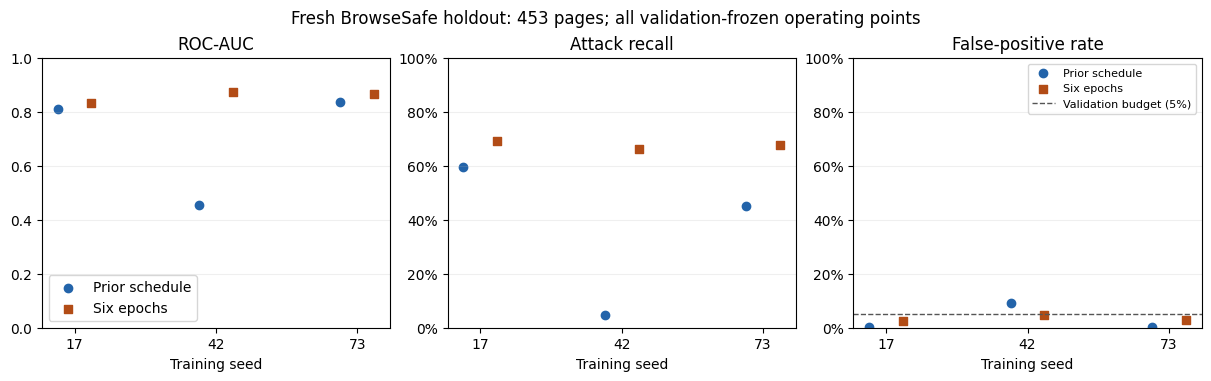

Nominal paired intervals and independent replay are computed after artifact retrieval.


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
result=json.loads((output/'holdout_results.json').read_text())
assert len(result['summaries'])==len(result['prior_summaries'])==6
for seed in [17,42,73]:
    for label,key in [('Prior schedule','prior_summaries'),('Six epochs','summaries')]:
        row=result[key][f'finetuned_{seed}']
        print(f"{seed} {label}: AUC={row['roc_auc']:.4f}, recall={row['recall']['value']:.2%}, FPR={row['fpr']['value']:.2%}")
fig,axes=plt.subplots(1,3,figsize=(12,3.7),layout='constrained')
for ax,metric,title in zip(axes,['roc_auc','recall','fpr'],['ROC-AUC','Attack recall','False-positive rate']):
    for offset,(label,key,color,marker) in zip([-.12,.12],[('Prior schedule','prior_summaries','#2364aa','o'),('Six epochs','summaries','#b24c16','s')]):
        values=[result[key][f'finetuned_{seed}'][metric] for seed in [17,42,73]]
        values=[v['value'] if isinstance(v,dict) else v for v in values]
        ax.scatter([i+offset for i in range(3)],values,label=label,color=color,marker=marker)
    ax.set(title=title,xticks=range(3),xticklabels=['17','42','73'],xlabel='Training seed',ylim=(0,1))
    if metric!='roc_auc': ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis='y',alpha=.2)
axes[0].legend()
axes[2].axhline(.05,color='#555555',ls='--',lw=1,label='Validation budget (5%)')
axes[2].legend(fontsize=8)
fig.suptitle('Fresh BrowseSafe holdout: 453 pages; all validation-frozen operating points')
fig.savefig(output/'schedule_comparison.png',dpi=180)
plt.show()
print('Nominal paired intervals and independent replay are computed after artifact retrieval.')


## Takeaways
Report recall together with actual false positives for every seed. A validation constraint is not a population guarantee. This is a BrowseSafe-only research experiment; unknown template relationships and source-label uncertainty remain. The 453-page holdout is consumed once evaluated.

Download all manifest files and logs before stopping the A100 session. Prior checkpoint files can be restored from their verified existing local copies. Avoid duplicating large result archives on the Mac.